# Mini-Project 1: UBOS District Population Forecaster


In [1]:
from pathlib import Path
import sys
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.population import (
    DistrictPopulation, LinearTrendForecaster,
    ExponentialGrowthForecaster, FibonacciRatioForecaster,
    forecast_metrics
)

SEED = 2026
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
print("Project root:", PROJECT_ROOT.resolve())
print("Random seed:", SEED)

Project root: /mnt/data/mini_project_1_population
Random seed: 2026


# 2. Create and validate the district data
Mbarara and Mbale are added districts

# 3. Descriptive statistics: `statistics` versus NumPy

`statistics.variance()` computes sample variance (divides by *n − 1*). `np.var()` 
defaults to population variance (divides by *n*). Setting `ddof=1` makes NumPy calculate sample variance. 
Standard deviation is the square root of variance.

## 4. Year on year growth and CAGR

Year-on-year growth is `(current / previous − 1) × 100`. CAGR summarises the compound annual rate between the first and last observations; it does not mean the population grew at that exact rate every year.

In [4]:
growth_rows, yoy_growth = [], {}
for name, district in districts.items():
    p = district.populations
    rates = (p[1:] / p[:-1] - 1) * 100
    yoy_growth[name] = rates
    cagr = ((p[-1] / p[0]) ** (1 / (district.years[-1] - district.years[0])) - 1) * 100
    growth_rows.append({
        "District": name,
        "Mean annual growth (%)": float(np.mean(rates)),
        "Minimum YoY growth (%)": float(np.min(rates)),
        "Maximum YoY growth (%)": float(np.max(rates)),
        "CAGR 2015–2024 (%)": float(cagr),
    })
growth_df = pd.DataFrame(growth_rows).set_index("District")
display(growth_df.round(2))
fastest = growth_df["CAGR 2015–2024 (%)"].idxmax()
print(f"Fastest relative growth by CAGR: {fastest} ({growth_df.loc[fastest, 'CAGR 2015–2024 (%)']:.2f}% per year).")

,Mean annual growth (%),Minimum YoY growth (%),Maximum YoY growth (%),CAGR 2015–2024 (%)
District,,,,
Kampala,4.61,3.85,5.63,4.61
Wakiso,6.47,5.26,7.48,6.47
Gulu,4.61,3.12,5.81,4.61
Mbarara,4.35,3.59,5.00,4.35
Mbale,3.07,2.50,3.45,3.07


Fastest relative growth by CAGR: Wakiso (6.47% per year).


## 5. Validate the forecasting models

In [5]:
MODEL_FACTORIES = {
    "Linear trend": LinearTrendForecaster,
    "Exponential/CAGR": ExponentialGrowthForecaster,
    "Fibonacci ratio": FibonacciRatioForecaster,
}
train_mask = years <= 2021
test_mask = years >= 2022
train_years, test_years = years[train_mask], years[test_mask]
validation_results, best_models = {}, {}

for name, district in districts.items():
    y_train, y_test = district.populations[train_mask], district.populations[test_mask]
    rows = []
    for model_name, factory in MODEL_FACTORIES.items():
        model = factory().fit(train_years, y_train)
        prediction = model.predict(len(test_years))
        rows.append({"Model": model_name, **forecast_metrics(y_test, prediction)})
    result_df = pd.DataFrame(rows).sort_values("MAPE_percent").reset_index(drop=True)
    validation_results[name] = result_df
    best_models[name] = result_df.loc[0, "Model"]
    print(f"\n{name}: validation metrics (2022–2024)")
    display(result_df.round(3))
    print("Selected by lowest MAPE:", best_models[name])


Kampala: validation metrics (2022–2024)


,Model,MAE,RMSE,MAPE_percent
0,Exponential/CAGR,9.619,10.385,0.551
1,Linear trend,37.619,38.975,2.165
2,Fibonacci ratio,3543.333,4025.357,201.995


Selected by lowest MAPE: Exponential/CAGR

Wakiso: validation metrics (2022–2024)


,Model,MAE,RMSE,MAPE_percent
0,Exponential/CAGR,6.802,8.049,0.420
1,Linear trend,49.405,52.368,3.094
2,Fibonacci ratio,3060.000,3479.866,189.870


Selected by lowest MAPE: Exponential/CAGR

Gulu: validation metrics (2022–2024)


...

Selected by lowest MAPE: Exponential/CAGR

Mbarara: validation metrics (2022–2024)


,Model,MAE,RMSE,MAPE_percent
0,Exponential/CAGR,2.711,3.163,0.971
1,Linear trend,7.857,8.509,2.836
2,Fibonacci ratio,557.000,632.719,200.160


Selected by lowest MAPE: Exponential/CAGR

Mbale: validation metrics (2022–2024)


,Model,MAE,RMSE,MAPE_percent
0,Exponential/CAGR,5.563,6.151,0.902
1,Linear trend,12.012,12.816,1.953
2,Fibonacci ratio,1290.667,1465.629,208.906


Selected by lowest MAPE: Exponential/CAGR


### Model-selection note

The model with the lowest MAPE on the three-year test period is selected for each district. Because the test set is short, the winning model may not remain best in future years. The Fibonacci-ratio model is included because the assignment requires it, but it has no demographic foundation.

## 6. Forecast population for 2025–2029 and compare variance

In [6]:
future_years = np.arange(2025, 2030)
forecast_rows, forecast_values = [], {}
for name, district in districts.items():
    model_name = best_models[name]
    model = MODEL_FACTORIES[model_name]().fit(district.years, district.populations)
    prediction = model.predict(5)
    forecast_values[name] = prediction
    forecast_rows.append({
        "District": name,
        "Selected model": model_name,
        **{str(year): float(value) for year, value in zip(future_years, prediction)},
        "Actual variance (2015–2024)": float(np.var(district.populations, ddof=1)),
        "Forecast variance (2025–2029)": float(np.var(prediction, ddof=1)),
    })
forecast_df = pd.DataFrame(forecast_rows).set_index("District")
display(forecast_df.round(2))

,Selected model,2025,2026,2027,2028,2029,Actual variance (2015–2024),Forecast variance (2025–2029)
District,,,,,,,,
Kampala,Exponential/CAGR,1882.95,1969.72,2060.49,2155.44,2254.76,42601.11,21607.68
Wakiso,Exponential/CAGR,1778.03,1893.04,2015.49,2145.86,2284.67,60066.67,40131.36
Gulu,Exponential/CAGR,502.12,525.26,549.46,574.78,601.27,2885.83,1536.55
Mbarara,Exponential/CAGR,298.43,311.41,324.94,339.07,353.81,942.67,479.31
Mbale,Exponential/CAGR,649.33,669.24,689.77,710.93,732.74,2573.57,1087.38


A lower forecast variance than historical variance means the forecast values vary less around their own mean within those periods. 

## 7. Plot actual, fitted and forecast values

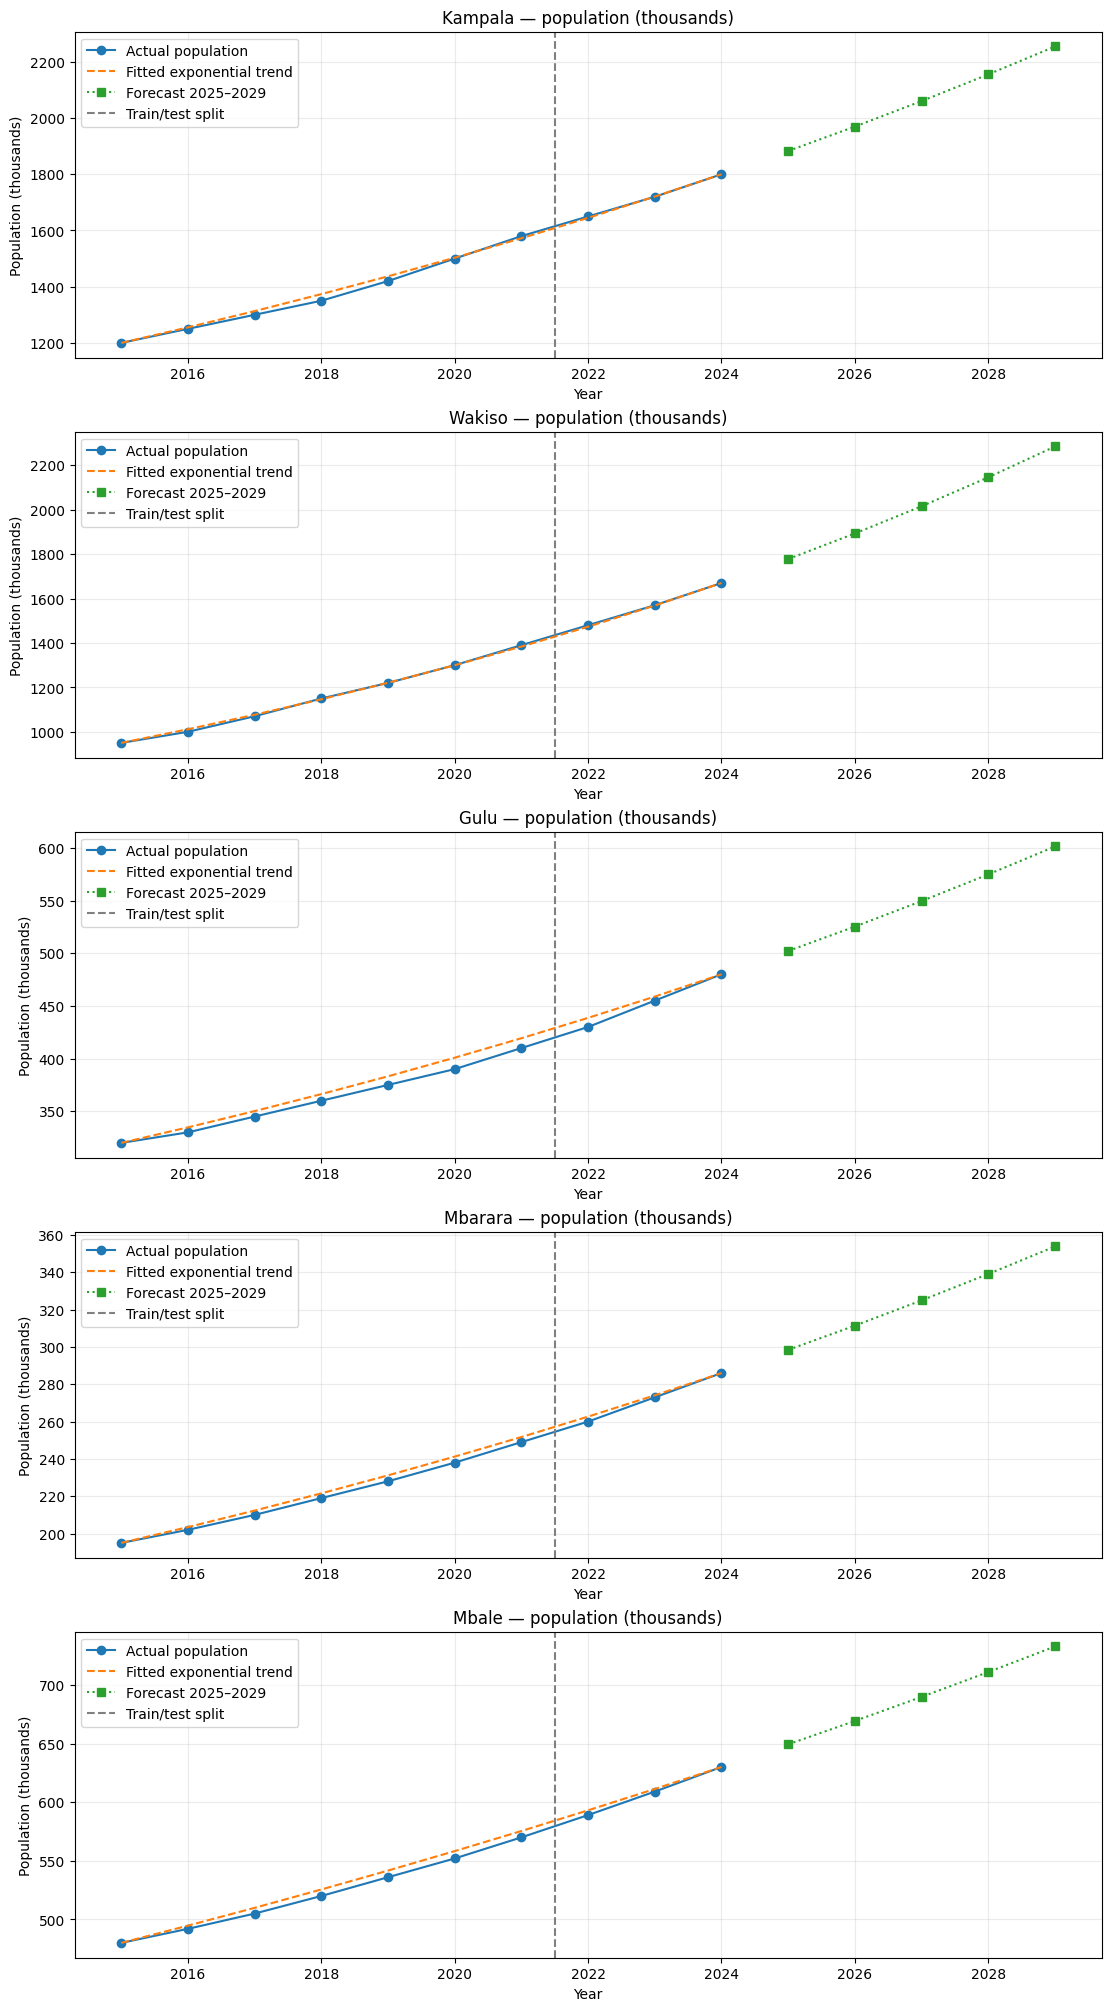

In [7]:
fig, axes = plt.subplots(len(districts), 1, figsize=(11, 4 * len(districts)), constrained_layout=True)
for ax, (name, district) in zip(axes, districts.items()):
    model_name = best_models[name]
    factory = MODEL_FACTORIES[model_name]
    ax.plot(district.years, district.populations, marker="o", label="Actual population")
    # Show a historical trend fit for the two standard trend models.
    if model_name == "Linear trend":
        fitted_model = LinearTrendForecaster().fit(district.years, district.populations)
        fitted = fitted_model.slope * district.years + fitted_model.intercept
        ax.plot(district.years, fitted, linestyle="--", label="Fitted linear trend")
    elif model_name == "Exponential/CAGR":
        fitted_model = ExponentialGrowthForecaster().fit(district.years, district.populations)
        fitted = district.populations[0] * (1 + fitted_model.cagr) ** (district.years - district.years[0])
        ax.plot(district.years, fitted, linestyle="--", label="Fitted exponential trend")
    else:
        ax.text(0.02, 0.92, "Fibonacci model: no conventional fitted curve",
                transform=ax.transAxes, va="top")
    ax.plot(future_years, forecast_values[name], marker="s", linestyle=":", label="Forecast 2025–2029")
    ax.axvline(2021.5, color="grey", linestyle="--", label="Train/test split")
    ax.set_title(f"{name} — population (thousands)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Population (thousands)")
    ax.grid(True, alpha=0.25)
    ax.legend()
fig.savefig(PROJECT_ROOT / "figures" / "population_forecasts.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Primary-school classroom planning estimate

The assignment assumes 18% of the population is of primary-school age and a classroom holds 53 pupils. Population values are in thousands, so multiply by 1,000 first. The calculation estimates total classroom capacity for this age group in 2029. The number of *additional* classrooms cannot be known without existing classroom capacity.

In [8]:
classroom_rows = []
for name, prediction in forecast_values.items():
    population_2029 = float(prediction[-1]) * 1000
    primary_age_pupils = population_2029 * 0.18
    classrooms = int(np.ceil(primary_age_pupils / 53))
    classroom_rows.append({
        "District": name,
        "Forecast population 2029 (people)": int(round(population_2029)),
        "Estimated primary-school-age population": int(round(primary_age_pupils)),
        "Estimated classrooms for this cohort": classrooms,
        "Existing capacity supplied?": "No",
    })
classroom_df = pd.DataFrame(classroom_rows).set_index("District")
display(classroom_df)

,Forecast population 2029 (people),Estimated primary-school-age population,Estimated classrooms for this cohort,Existing capacity supplied?
District,,,,
Kampala,2254763,405857,7658,No
Wakiso,2284671,411241,7760,No
Gulu,601270,108229,2043,No
Mbarara,353812,63686,1202,No
Mbale,732742,131894,2489,No


## 9. Findings & Limitations

This analysis compares five district population series using three forecasting methods. The models are trained on 2015–2021 and evaluated on 2022–2024. The model selected for each district has the lowest MAPE on the held-out years. This is useful because the test observations are not used to fit the models. However, only three test years are available, so one unusual year can change the ranking.

The linear model assumes a roughly constant absolute increase each year, while the exponential model assumes a constant compound growth rate. Neither model explicitly accounts for migration, fertility, mortality, boundary changes or local development. The Fibonacci-ratio method is especially weak as a population model because its ratios do not represent a known demographic process and may produce implausibly large increases. It is included to meet the assignment requirement, not recommended for actual district planning.

The classroom calculation applies the assumed 18% to the 2029 forecast and divides by 53 pupils per classroom, rounding up. It estimates total capacity for the assumed age group, not additional classrooms. Existing classroom numbers, enrolment rates, classroom utilisation and school-age population data are unavailable. Kampala, Wakiso and Gulu are based on the assignment's illustrative data; Mbarara and Mbale are also illustrative additions. Real planning should use cited official population data and include uncertainty estimates.

## 10. Extension: bootstrap residual prediction intervals

In [9]:
def fitted_and_residuals(model_name, years_arr, values):
    values = np.asarray(values, dtype=float)
    years_arr = np.asarray(years_arr, dtype=int)
    if model_name == "Linear trend":
        model = LinearTrendForecaster().fit(years_arr, values)
        fitted = model.slope * years_arr + model.intercept
    elif model_name == "Exponential/CAGR":
        model = ExponentialGrowthForecaster().fit(years_arr, values)
        fitted = values[0] * (1 + model.cagr) ** (years_arr - years_arr[0])
    else:
        return None, None
    return fitted, values - fitted


def bootstrap_prediction_interval(name, n_resamples=1000, seed=2026):
    if n_resamples < 1000:
        raise ValueError("Use at least 1,000 resamples.")
    district = districts[name]
    model_name = best_models[name]
    _, residuals = fitted_and_residuals(model_name, district.years, district.populations)
    if residuals is None:
        return None
    model = MODEL_FACTORIES[model_name]().fit(district.years, district.populations)
    point_forecast = model.predict(5)
    local_rng = np.random.default_rng(seed)
    simulated = np.empty((n_resamples, 5))
    for i in range(n_resamples):
        sampled_errors = local_rng.choice(residuals, size=5, replace=True)
        simulated[i] = np.maximum(0, point_forecast + sampled_errors)
    return pd.DataFrame({
        "Year": future_years,
        "Forecast": point_forecast,
        "Lower 95%": np.percentile(simulated, 2.5, axis=0),
        "Upper 95%": np.percentile(simulated, 97.5, axis=0),
    })

for district_name in districts:
    interval = bootstrap_prediction_interval(district_name, n_resamples=1000, seed=SEED)
    print(district_name, "— bootstrap interval")
    if interval is None:
        print("Not computed: selected Fibonacci model has no conventional fitted-residual construction.")
    else:
        display(interval.round(2))

Kampala — bootstrap interval


,Year,Forecast,Lower 95%,Upper 95%
0,2025,1882.95,1859.29,1890.50
1,2026,1969.72,1946.06,1977.27
2,2027,2060.49,2036.83,2068.04
3,2028,2155.44,2131.78,2162.99
4,2029,2254.76,2231.11,2262.32


Wakiso — bootstrap interval


,Year,Forecast,Lower 95%,Upper 95%
0,2025,1778.03,1766.57,1784.78
1,2026,1893.04,1881.59,1899.80
2,2027,2015.49,2004.04,2022.25
3,2028,2145.86,2134.41,2152.62
4,2029,2284.67,2273.22,2291.43


Gulu — bootstrap interval


,Year,Forecast,Lower 95%,Upper 95%
0,2025,502.12,491.27,502.12
1,2026,525.26,514.41,525.26
2,2027,549.46,538.62,549.46
3,2028,574.78,563.94,574.78
4,2029,601.27,590.42,601.27


Mbarara — bootstrap interval


,Year,Forecast,Lower 95%,Upper 95%
0,2025,298.43,295.20,298.43
1,2026,311.41,308.17,311.41
2,2027,324.94,321.71,324.94
3,2028,339.07,335.84,339.07
4,2029,353.81,350.58,353.81


Mbale — bootstrap interval


,Year,Forecast,Lower 95%,Upper 95%
0,2025,649.33,643.05,649.33
1,2026,669.24,662.96,669.24
2,2027,689.77,683.49,689.77
3,2028,710.93,704.65,710.93
4,2029,732.74,726.46,732.74
